# Lagrangian statistics and coherent structures
## 02 — Practical: HF-radar surface currents

The theory is in [`00-lagrangian-theory.ipynb`](00-lagrangian-theory.ipynb) and every diagnostic was validated on an analytic flow in [`01-lagrangian-bickley-jet.ipynb`](01-lagrangian-bickley-jet.ipynb). Here the **same functions** (`lagkit.py`) are applied to surface currents measured by HF radar in the **Gulf of Tonkin**.

Units in this notebook: **km** and **hours** (velocities are stored in m/s and converted with ×3.6; rates are quoted per day where that is easier to read).

### Before anything else: Lagrangian analysis needs continuous data

A particle is advected by integrating the velocity along its path. If the velocity is missing at one place for one hour, every particle that passes there is lost, and with it every statistic and every map value that depends on it. Raw HF-radar totals are **not** continuous: coverage changes from hour to hour with sea state, interference and antenna outages ([C4](#C4) shows what this does).

The Gulf of Tonkin file used here has therefore been **re-processed with a gap-filling method, 2DVar** (two-dimensional variational interpolation of the radial velocities; Yaremchuk & Sentchev 2009). The result is a field that is defined at every hour on a fixed footprint. Keep in mind what this implies:

- the footprint is fixed: the same cells are valid at all times;
- the field is **smooth**. A variational interpolation penalises small-scale divergence and vorticity, so sharp fronts and small eddies are damped. Expect broader and weaker Lagrangian structures than in a high-resolution model;
- filled values are estimates, and the file does not say which cells were observed and which were filled at a given hour.

| Section | Content | Theory |
|---|---|---|
| [C1](#C1) | Loading the data | |
| [C2](#C2) | First look and quality control | [A1](00-lagrangian-theory.ipynb#A1) |
| [C3](#C3) | Tides and inertial motions | |
| [C4](#C4) | Why continuous data: gaps | [A9](00-lagrangian-theory.ipynb#A9) |
| [C5](#C5) | Particle advection | [A1](00-lagrangian-theory.ipynb#A1), [A9](00-lagrangian-theory.ipynb#A9) |
| [C6](#C6) | Single-particle statistics | [A2](00-lagrangian-theory.ipynb#A2) |
| [C7](#C7) | Relative dispersion and FSLE statistic | [A3](00-lagrangian-theory.ipynb#A3), [A4](00-lagrangian-theory.ipynb#A4) |
| [C8](#C8) | FTLE | [A5](00-lagrangian-theory.ipynb#A5) |
| [C9](#C9) | FSLE map | [A6](00-lagrangian-theory.ipynb#A6) |
| [C10](#C10) | LAVD, eddies, and Okubo–Weiss | [A7](00-lagrangian-theory.ipynb#A7), [A8](00-lagrangian-theory.ipynb#A8) |
| [C11](#C11) | Summary and exercises | |

<a id="C0"></a>
## C0. Configuration

Everything that can be tuned is in this cell. The lengths and times are chosen for the Gulf of Tonkin footprint (about 220 × 260 km, 6 km grid).

In [1]:
import os
import time
import warnings

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import lagkit as lk

DATA_PATH = "data/hfr-got-2015-01.nc"      # Gulf of Tonkin HF radar, January 2015, hourly, 6 km, gap-filled with 2DVar
T_START, T_END = "2015-01-10", "2015-01-20"   # analysis period; the file must also hold 2 days before and after
DETIDE = "none"            # velocity used for the diagnostics: "none" (raw, tides included) | "godin" (residual)
GAP_MIN_COVERAGE = 0.7     # used only when data have gaps: footprint = cells valid this fraction of the time
GAP_MAX_HOURS = 6.0        # gaps up to this length are interpolated in time

DT = 0.5                   # integration time step [h]
DX_MAP = 1.0               # spacing of the particle grid used for the maps [km]
T_TRAJ = 72.0              # trajectories of C5 [h]
T_STATS = 120.0            # single-particle and pair statistics [h]
T_FTLE = 48.0              # FTLE integration time [h]
T_LAVD = 72.0              # LAVD integration time [h]
PAIR_D0 = 2.0              # smallest initial separation of the pairs [km]
PAIR_N_SEP = 9             # pairs are released at PAIR_D0 * sqrt(2)**n, n = 0 .. PAIR_N_SEP-1 (2 to 32 km)
FSLE_D0, FSLE_RATIO, FSLE_TMAX = 1.0, 1.5, 96.0    # FSLE map: delta_0 [km], delta_f / delta_0, maximum time [h]
PATCH = (40.0, 5.0)        # release patches of C5: offset from the centre and half-width [km]
EDDY_BOX, EDDY_MIN_R = 15.0, 5.0                   # eddy extraction: peak neighbourhood and minimum radius [km]
COAST_BOX = (104.5, 109.5, 16.0, 21.5)             # lon_min, lon_max, lat_min, lat_max of the coastline
COAST_CACHE = "data/coast_got_f.npz"
MIN_ROTATION = 0.5         # a LAVD contour counts as an eddy only if the water turns this many times during T_LAVD
CD_MAX = 0.01              # convexity deficiency allowed for an eddy boundary
N_SINGLE, N_PAIRS = 3000, 3000
MS_TO_KMH = 3.6

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "image.origin": "lower"})
warnings.filterwarnings("ignore", message="Mean of empty slice")
t_notebook = time.time()

<a id="C1"></a>
## C1. Loading the data

`lk.load_surface_currents` reads a NetCDF file of gridded currents and returns a dataset with dimensions `(time, lat, lon)` and variables `u`, `v` in m/s. It recognises the velocity by its CF `standard_name` or by common variable names, accepts 1-D or 2-D longitude/latitude, converts cm/s to m/s, and applies quality flags when the file provides them. The same function reads a model surface field.

The cell below stops with a clear message if the file is missing. There is no silent replacement by synthetic data.

In [2]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"'{DATA_PATH}' not found. Put the Gulf of Tonkin HF-radar file in data/ or edit DATA_PATH in C0.")
PATH = DATA_PATH
PAD_H = 48.0                                         # extra hours on each side, needed by the tidal filter

ds_pad = lk.load_surface_currents(PATH, T_START, f"{T_END}T23:00", pad_hours=PAD_H)
in_window = (ds_pad.time.values >= np.datetime64(T_START)) & (ds_pad.time.values <= np.datetime64(f"{T_END}T23:00"))
ds = ds_pad.isel(time=in_window)
have_pad = (ds_pad.time.values[0] <= np.datetime64(T_START) - np.timedelta64(36, "h")) and \
           (ds_pad.time.values[-1] >= np.datetime64(f"{T_END}T23:00") + np.timedelta64(36, "h"))
if not have_pad:
    print("WARNING: the file does not hold 36 h of data before and after the period; the residual (Godin) field "
          "will be undefined near its ends. Choose a period further from the ends of the file.")
print(f"source : {PATH}")
print(f"period : {str(ds.time.values[0])[:16]} to {str(ds.time.values[-1])[:16]}  ({ds.sizes['time']} fields)")
print(f"vectors rejected by the quality flags: {ds_pad.attrs['n_flagged']}")
dt_h = np.unique(np.diff(ds.time.values) / np.timedelta64(1, "h"))
print(f"time step(s): {dt_h} h;  grid: {ds.sizes['lat']} x {ds.sizes['lon']}")
ds

source : data/hfr-got-2015-01.nc
period : 2015-01-10T00:00 to 2015-01-20T23:00  (264 fields)
vectors rejected by the quality flags: 0
time step(s): [1.] h;  grid: 65 x 52


<xarray.Dataset> Size: 14MB
Dimensions:  (time: 264, lat: 65, lon: 52)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2015-01-10 ... 2015-01-20T23:00:00
  * lat      (lat) float64 520B 17.02 17.07 17.13 17.18 ... 20.35 20.41 20.46
  * lon      (lon) float64 416B 105.6 105.6 105.7 105.7 ... 108.4 108.4 108.5
Data variables:
    u        (time, lat, lon) float64 7MB nan nan nan nan ... nan nan nan nan
    v        (time, lat, lon) float64 7MB nan nan nan nan ... nan nan nan nan
Attributes:
    source:     data/hfr-got-2015-01.nc
    period:     2015-01-08T00:00 to 2015-01-22T23:00
    n_flagged:  0
    u_name:     U
    v_name:     V

Positions are integrated in a **local Cartesian frame** in km (equirectangular projection about the centre of the grid); longitude and latitude are only used for loading. `lk.dataset_to_km` does the conversion and expresses time in hours since the first field.

If a file with gaps is given instead, they are filled here with `lk.fill_gaps`; [C4](#C4) explains how and why. The 2DVar Gulf of Tonkin file passes through unchanged.

In [3]:
pad_km = lk.dataset_to_km(ds_pad)                    # x, y in km (padded record, needed again in C3)
t_rel = (ds_pad.time.values[in_window] - np.datetime64(T_START)) / np.timedelta64(1, "h")
crop = lambda d: d.isel(time=in_window).assign_coords(time=t_rel)     # analysis window, time in hours since T_START
raw_km = crop(pad_km)
valid_t = np.isfinite(raw_km.u.values) & np.isfinite(raw_km.v.values)
ever = valid_t.any(axis=0)
has_gaps = bool((valid_t[:, ever].mean(axis=0) < 1).any())
if has_gaps:
    pad_filled, foot, gap_stats = lk.fill_gaps(pad_km, GAP_MIN_COVERAGE, GAP_MAX_HOURS)
    print(f"gaps found -> filled. Footprint: {foot.sum()} of {ever.sum()} cells; valid inside it: raw {100 * gap_stats['raw']:.0f}%,"
          f" after time interpolation {100 * gap_stats['time']:.0f}%, after spatial fill {100 * gap_stats['space']:.0f}%")
else:
    pad_filled, foot = pad_km, ever
    print(f"no gaps: the same {foot.sum()} cells are valid at all {raw_km.sizes['time']} times (continuous data)")
hk = crop(pad_filled)

x, y, t = hk.x.values, hk.y.values, hk.time.values
dx, dy = x[1] - x[0], y[1] - y[0]
LON0, LAT0 = hk.attrs["lon0"], hk.attrs["lat0"]
F_COR = 2 * 7.2921e-5 * np.sin(np.deg2rad(LAT0)) * 3600          # Coriolis parameter [1/h]
T_INERTIAL = 2 * np.pi / F_COR
print(f"grid spacing: dx = {dx:.2f} km, dy = {dy:.2f} km;  footprint about {np.ptp(x[foot.any(0)]):.0f} x {np.ptp(y[foot.any(1)]):.0f} km")
print(f"centre: {LON0:.2f}E, {LAT0:.2f}N;  inertial period 2 pi / f = {T_INERTIAL:.1f} h")

COAST = lk.coastline(*COAST_BOX, scale="f", cache=COAST_CACHE)


def deco(ax, pad=25.0):
    # km axes, footprint outline and coastline
    ax.set(xlabel="x [km]", ylabel="y [km]", aspect="equal")
    ax.contour(x, y, foot.astype(float), levels=[0.5], colors="0.3", linewidths=0.7)
    lk.plot_coastline(ax, COAST, LON0, LAT0)
    fx, fy = x[foot.any(axis=0)], y[foot.any(axis=1)]
    ax.set(xlim=(fx[0] - 2.5 * pad, fx[-1] + pad), ylim=(fy[0] - pad, fy[-1] + pad))

no gaps: the same 1090 cells are valid at all 264 times (continuous data)
grid spacing: dx = 6.00 km, dy = 5.98 km;  footprint about 222 x 257 km
centre: 107.03E, 18.74N;  inertial period 2 pi / f = 37.2 h


<a id="C2"></a>
## C2. First look and quality control

Before any Lagrangian calculation, look at the data: where and when is it valid, how strong is the flow, how strong are its gradients.

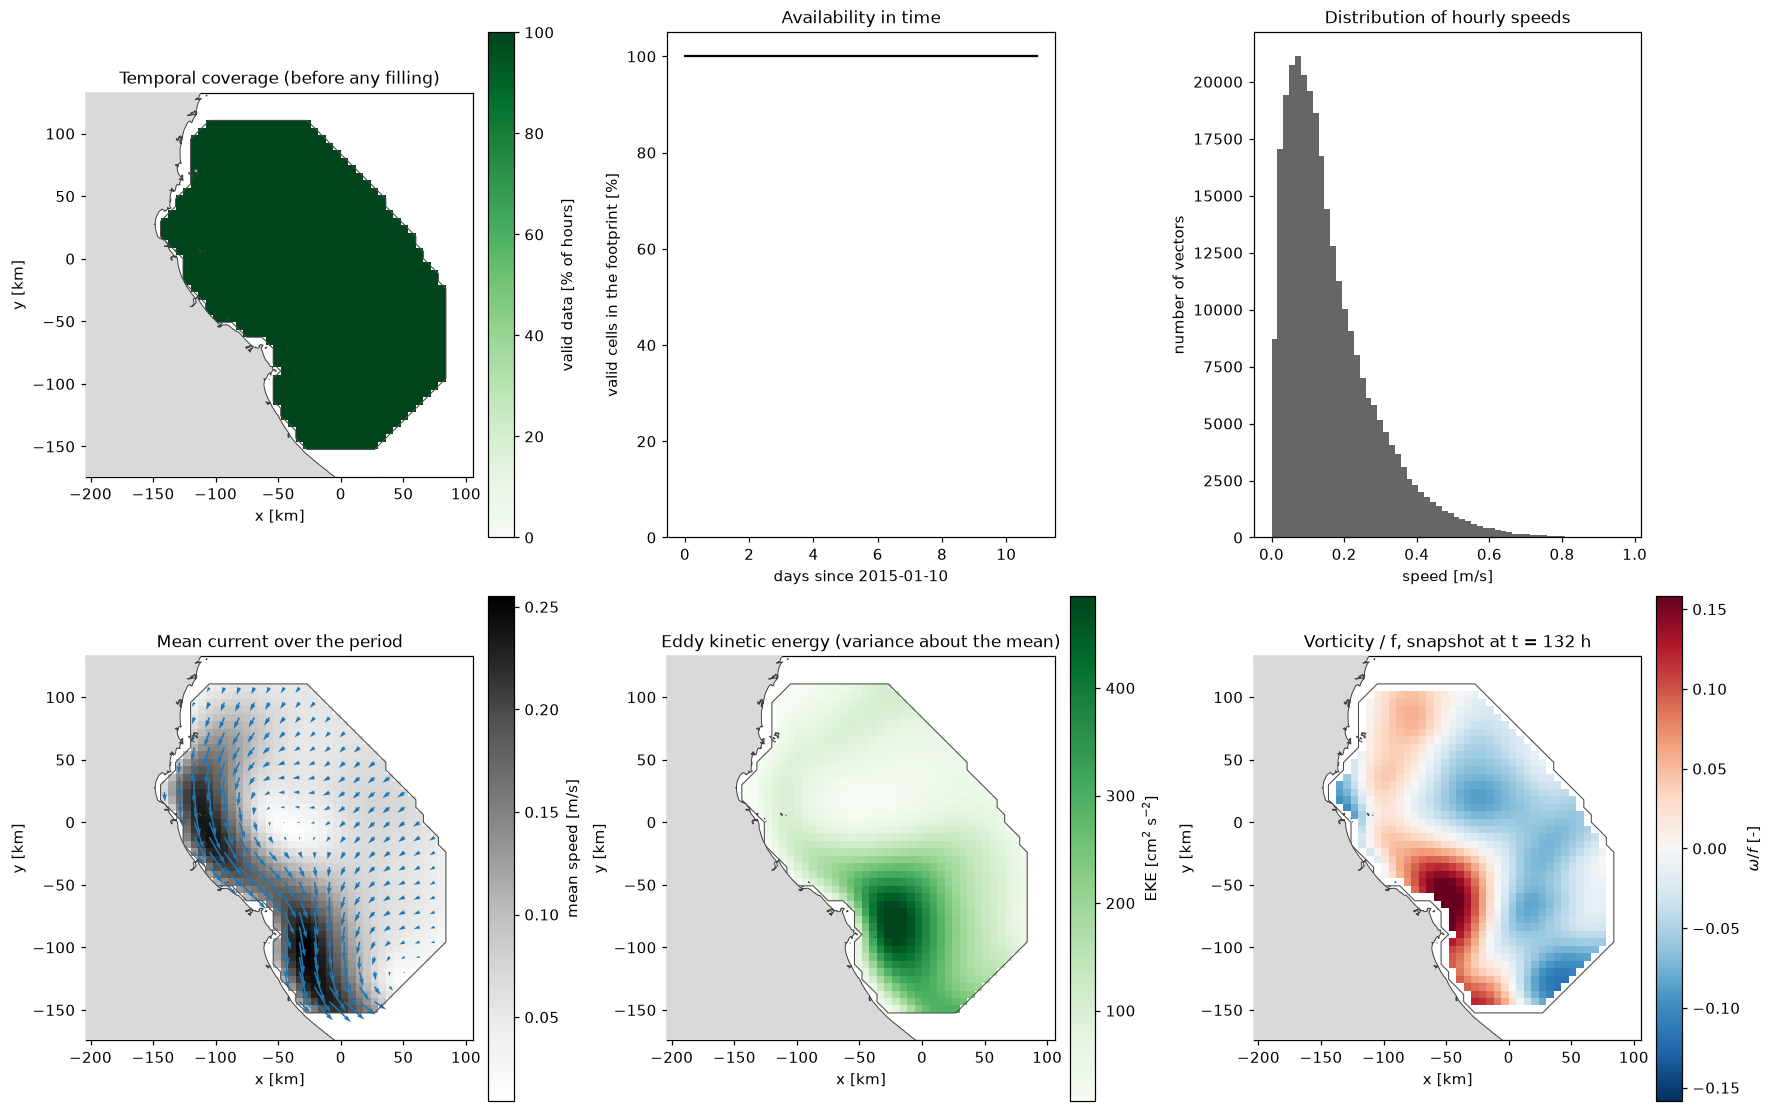

speed: mean 0.161 m/s, 99th percentile 0.581 m/s, max 0.97 m/s
mean-flow speed 0.101 m/s;  mean EKE 139 cm2/s2
rms vorticity / f = 0.10
largest displacement in one time step of the integration (0.5 h): 1.7 km (grid spacing 6.0 km)


In [4]:
um, vm = hk.u.mean("time").values, hk.v.mean("time").values
eke = 0.5 * (hk.u.var("time") + hk.v.var("time")).values                    # m2/s2
om_all = lk.vorticity(hk.u.values * MS_TO_KMH, hk.v.values * MS_TO_KMH, dx, dy)   # 1/h
speed = np.hypot(hk.u.values, hk.v.values)

fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
ax = axes[0, 0]
lk.plot_field(ax, x, y, np.where(ever, 100 * valid_t.mean(axis=0), np.nan), kind="coverage", label="valid data [% of hours]",
              vmin=0, vmax=100, robust=False, title="Temporal coverage (before any filling)")
deco(ax)
ax = axes[0, 1]
ax.plot(t / 24, 100 * valid_t[:, foot].mean(axis=1), "k")
ax.set(xlabel=f"days since {T_START}", ylabel="valid cells in the footprint [%]", ylim=(0, 105), title="Availability in time")
ax = axes[0, 2]
ax.hist(speed[np.isfinite(speed)], bins=60, color="0.4")
ax.set(xlabel="speed [m/s]", ylabel="number of vectors", title="Distribution of hourly speeds")
ax = axes[1, 0]
lk.plot_field(ax, x, y, np.hypot(um, vm), kind="speed", label="mean speed [m/s]", robust=False, title="Mean current over the period")
st = max(int(round(12.0 / dx)), 1)
ax.quiver(x[::st], y[::st], um[::st, ::st], vm[::st, ::st], color="tab:blue", scale=3, width=0.004)
deco(ax)
ax = axes[1, 1]
lk.plot_field(ax, x, y, np.where(foot, eke * 1e4, np.nan), kind="Greens", label="EKE [cm$^2$ s$^{-2}$]", title="Eddy kinetic energy (variance about the mean)")
deco(ax)
ax = axes[1, 2]
k_mid = len(t) // 2
lk.plot_field(ax, x, y, om_all[k_mid] / F_COR, kind="vorticity", label=r"$\omega/f$ [-]", title=f"Vorticity / f, snapshot at t = {t[k_mid]:.0f} h")
deco(ax)
plt.show()

print(f"speed: mean {np.nanmean(speed):.3f} m/s, 99th percentile {np.nanpercentile(speed, 99):.3f} m/s, max {np.nanmax(speed):.2f} m/s")
print(f"mean-flow speed {np.nanmean(np.hypot(um, vm)):.3f} m/s;  mean EKE {np.nanmean(eke[foot]) * 1e4:.0f} cm2/s2")
print(f"rms vorticity / f = {np.sqrt(np.nanmean(om_all ** 2)) / F_COR:.2f}")
print(f"largest displacement in one time step of the integration ({DT} h): {np.nanmax(speed) * MS_TO_KMH * DT:.1f} km (grid spacing {dx:.1f} km)")

**What HF radar measures.** The radar senses the Doppler shift of waves about half the radar wavelength long, so the current it reports is an average over roughly the top metre (depending on frequency), over a cell of a few kilometres and over about an hour. It includes part of the wave-induced Stokes drift. The horizontal velocity at the surface is **not** non-divergent ([A1](00-lagrangian-theory.ipynb#A1)), and noise in the totals adds spurious divergence.

*Site notes for the instructor to complete: radar stations, operating frequency, angular and range resolution, period of operation, and the settings of the 2DVar re-processing for the Gulf of Tonkin system.*

**Discussion.** - **Coverage.** The same 1090 cells are valid at every hour: the top row is what continuous, gap-filled data look like. [C4](#C4) shows what the same data look like with gaps.
- **Mean current.** A southward current follows the coast, up to 0.25 m/s, typical of the winter monsoon. Offshore the mean flow is weak.
- **Variability.** The eddy kinetic energy is largest in the south (more than 400 cm² s⁻²). Section C3 shows that most of it is tidal. Hourly speeds average 0.16 m/s and reach about 1 m/s.
- **Gradients are weak and smooth.** The vorticity is at most ±0.15 $f$ (rms 0.10 $f$), with structures tens of kilometres wide and nothing at the grid scale. This is the signature of the 6 km resolution and of the 2DVar interpolation. Lagrangian structures come from velocity *gradients*, so this panel already tells you to expect broad, weak features.
- **Numerical check.** The fastest particle moves 1.7 km per integration step, well below the 6 km grid spacing, so the time step is adequate ([A9](00-lagrangian-theory.ipynb#A9)).

<a id="C3"></a>
## C3. Tides and inertial motions

The Gulf of Tonkin has some of the strongest **diurnal** tides in the world (K1 and O1, periods 23.9 and 25.8 h). At this latitude the inertial period is also long, about 37 h, so inertial oscillations are close to the diurnal band.

Two velocity fields are useful, for different questions:

- the **raw** hourly field contains the tides. It is what a floating object actually feels, so it is the field to use to predict where something will go;
- the **residual** (detided, subtidal) field shows the slower circulation that produces net transport over several days.

The residual is obtained here with the **Godin filter**, three successive running means of 24, 24 and 25 hours (`lk.godin_filter`). It needs 35 hours of data on each side, which is why the loader took two extra days at each end. With a record of several months, harmonic analysis of each grid point (for example with the `utide` package) is the alternative; ten days are far too short to separate K1 from O1.

residual field finite inside the footprint: 100%
footprint-mean u, 31 days: variance in the diurnal band (20-30 h) 80%, semidiurnal (11-14 h) 12%, slower than 2 days 5%
footprint-mean v, 31 days: variance in the diurnal band (20-30 h) 75%, semidiurnal (11-14 h) 2%, slower than 2 days 21%
analysis window: the Godin filter removes 85% of the velocity variance


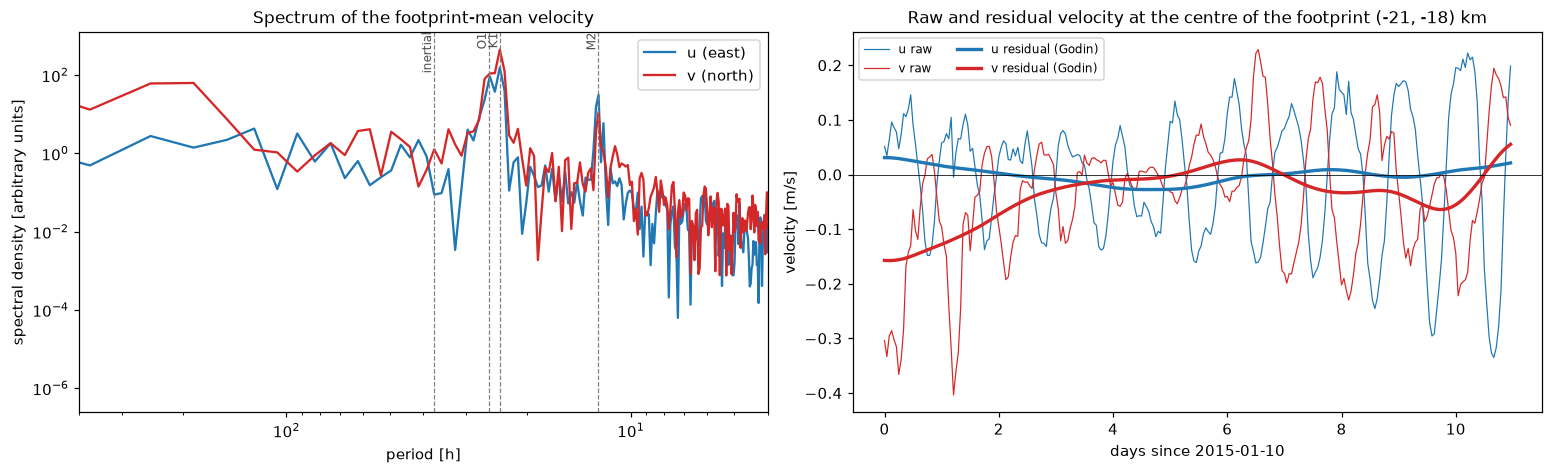

In [5]:
# Residual (subtidal) field: filter the padded record, then keep the analysis window
res_km = crop(lk.godin_filter(pad_filled))
fields = {"raw": hk, "residual": res_km}
print("residual field finite inside the footprint:", f"{100 * np.isfinite(res_km.u.values[:, foot]).mean():.0f}%")

# Spectrum of the footprint-mean velocity, from the whole file (a longer record resolves the tidal bands better)
long = lk.load_surface_currents(PATH)                                        # the whole file
fl = xr.DataArray(foot, dims=("lat", "lon"))
series = {n: np.nan_to_num(long[n].where(fl).mean(("lat", "lon")).values, nan=float(long[n].where(fl).mean())) for n in ("u", "v")}
freq = np.fft.rfftfreq(len(long.time), 1.0)                                  # cycles per hour
psd = {n: np.abs(np.fft.rfft((s - s.mean()) * np.hanning(len(s)))) ** 2 for n, s in series.items()}
band = lambda P_, lo, hi: P_[(freq > 1 / hi) & (freq < 1 / lo)].sum() / P_[1:].sum()
for n in ("u", "v"):
    print(f"footprint-mean {n}, {len(long.time) / 24:.0f} days: variance in the diurnal band (20-30 h) {100 * band(psd[n], 20, 30):.0f}%,"
          f" semidiurnal (11-14 h) {100 * band(psd[n], 11, 14):.0f}%, slower than 2 days {100 * band(psd[n], 48, 1e9):.0f}%")
var_raw = np.nanmean(hk.u.var("time").values[foot] + hk.v.var("time").values[foot])
var_res = np.nanmean(res_km.u.var("time").values[foot] + res_km.v.var("time").values[foot])
print(f"analysis window: the Godin filter removes {100 * (1 - var_res / var_raw):.0f}% of the velocity variance")

jc, ic = np.argwhere(foot)[np.argmin(np.hypot(*(np.argwhere(foot) - np.argwhere(foot).mean(0)).T))]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
ax = axes[0]
with np.errstate(divide="ignore"):
    ax.loglog(1 / freq[1:], psd["u"][1:], color="tab:blue", label="u (east)")
    ax.loglog(1 / freq[1:], psd["v"][1:], color="tab:red", label="v (north)")
for per, lab in ((12.42, "M2"), (23.93, "K1"), (25.82, "O1"), (T_INERTIAL, "inertial")):
    ax.axvline(per, color="0.5", lw=0.8, ls="--")
    ax.text(per, ax.get_ylim()[1], lab, rotation=90, va="top", ha="right", fontsize=8, color="0.3")
ax.set(xlabel="period [h]", ylabel="spectral density [arbitrary units]", xlim=(4, 400), title="Spectrum of the footprint-mean velocity")
ax.invert_xaxis()
ax.legend()
ax = axes[1]
ax.plot(t / 24, hk.u.values[:, jc, ic], color="tab:blue", lw=0.8, label="u raw")
ax.plot(t / 24, hk.v.values[:, jc, ic], color="tab:red", lw=0.8, label="v raw")
ax.plot(t / 24, res_km.u.values[:, jc, ic], color="tab:blue", lw=2.2, label="u residual (Godin)")
ax.plot(t / 24, res_km.v.values[:, jc, ic], color="tab:red", lw=2.2, label="v residual (Godin)")
ax.axhline(0, color="k", lw=0.5)
ax.set(xlabel=f"days since {T_START}", ylabel="velocity [m/s]", title=f"Raw and residual velocity at the centre of the footprint ({x[ic]:.0f}, {y[jc]:.0f}) km")
ax.legend(ncol=2, fontsize=8)
plt.show()

**Discussion.** - **The flow is dominated by the diurnal tide.** In the spectrum the two largest peaks are at K1 and O1, with a smaller one at M2. The diurnal band holds about three quarters of the variance of the footprint-mean velocity; no separate inertial peak stands out.
- **The Godin filter removes 85% of the velocity variance** in this window. What is left (thick lines) varies over several days: at the centre of the footprint a southward flow of 0.15 m/s that relaxes during the period.
- So the two fields are very different in amplitude. Whether they also differ in their Lagrangian structures is a separate question, answered in [C8](#C8).
- Ten days cannot resolve K1 from O1 (their beat period is 13.7 days), which is why a filter, and not a harmonic fit, is used on a short window.

<a id="C4"></a>
## C4. Why continuous data: what gaps do

The integrator of `lagkit` never extrapolates: when a particle reaches a place or a time where the velocity is missing, it is **frozen and flagged**, and its *exit time* is recorded ([A9](00-lagrangian-theory.ipynb#A9)). With a continuous field this only happens at the edge of the footprint. With raw radar totals it happens everywhere.

The cell below demonstrates it. Since the 2DVar field is continuous, we know the "truth" and can **take data away** in the way a real radar loses them:

- every cell drops out now and then for a few hours (weak signal, interference);
- a few times the whole radar is off the air (here for 3, 6 and 12 hours).

The same particles are then advected three times: in the complete 2DVar field, in the field with gaps, and in the field with gaps after the simple filling of `lk.fill_gaps`:

1. keep only the cells that work most of the time (the footprint);
2. interpolate linearly in time across short gaps;
3. fill what remains from the neighbouring cells;
4. as a last resort, interpolate in time across long outages of the whole radar.

This is a teaching tool. Operational systems fill gaps with methods that use the measurement geometry and the statistics or dynamics of the flow: **2DVar** (used for this data set), open-boundary modal analysis (OMA), or DINEOF.

data removed: 16% of the footprint-hours; footprint kept by the filling: 1088 of 1090 cells
valid inside the footprint: with gaps 84%  ->  time interpolation 91%  ->  spatial fill 95%  ->  final 100%
error of the simple filling where data were removed: rms 0.097 m/s (rms speed of the true field there: 0.225 m/s)
  complete (2DVar)      : particles still tracked after 6 h  93%, 24 h  88%, 72 h  73%; median tracking time 72 h
  with gaps             : particles still tracked after 6 h  38%, 24 h   5%, 72 h   0%; median tracking time 4 h


  gaps + simple filling : particles still tracked after 6 h  92%, 24 h  86%, 72 h  71%; median tracking time 72 h
  trajectories, simple filling vs complete field: mean separation 0.1 km after 24 h, 0.5 km after 48 h, 0.5 km after 72 h


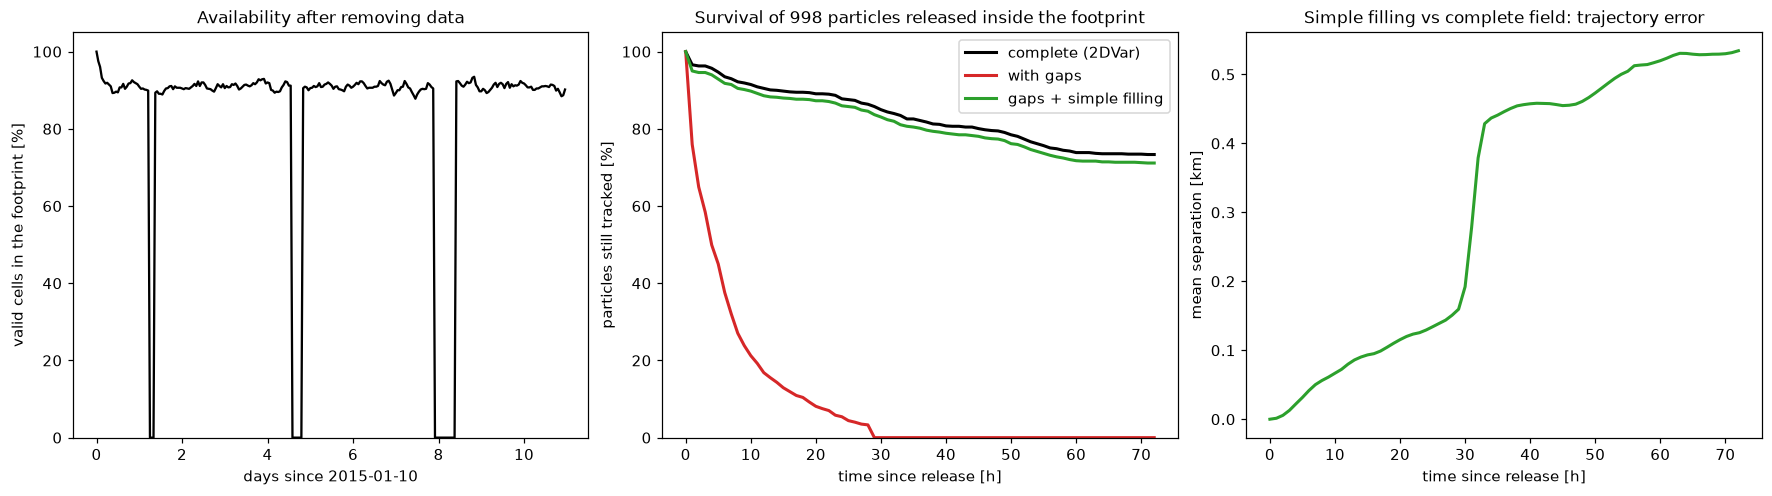

In [6]:
# 1. Remove data from the continuous field, the way a radar loses them
g_rng = np.random.default_rng(7)
nt = hk.sizes["time"]
gap = np.zeros(hk.u.shape, bool)
for j, i in zip(*np.nonzero(foot)):                       # cell drop-outs: gaps of 1-8 h, about 10% of the time
    k = 0
    while k < nt:
        k += int(g_rng.exponential(45.0)) + 1
        n = int(g_rng.integers(1, 9))
        gap[k:k + n, j, i] = True
        k += n
for start, length in ((30, 3), (110, 6), (190, 12)):      # whole-radar outages [h since T_START, hours]
    gap[start:start + length] = True
gap &= foot
gappy = hk.where(~xr.DataArray(gap, dims=("time", "y", "x")))
simple, foot_s, st = lk.fill_gaps(gappy, GAP_MIN_COVERAGE, GAP_MAX_HOURS)
filled_here = gap & foot_s
err = np.hypot(simple.u.values - hk.u.values, simple.v.values - hk.v.values)[filled_here]
print(f"data removed: {100 * gap[:, foot].mean():.0f}% of the footprint-hours; footprint kept by the filling: {foot_s.sum()} of {foot.sum()} cells")
print(f"valid inside the footprint: with gaps {100 * st['raw']:.0f}%  ->  time interpolation {100 * st['time']:.0f}%  ->  spatial fill {100 * st['space']:.0f}%  ->  final {100 * st['final']:.0f}%")
print(f"error of the simple filling where data were removed: rms {np.sqrt(np.mean(err ** 2)):.3f} m/s"
      f" (rms speed of the true field there: {np.sqrt(np.mean(np.hypot(hk.u.values, hk.v.values)[filled_here] ** 2)):.3f} m/s)")

# 2. Advect the same particles in the three fields
T_DEMO = 72.0
Xn, Yn = np.meshgrid(x, y)
start_ok = np.isfinite(lk.grid_interpolator(hk, "u", "v")(Xn, Yn, 0.0)[0])       # interior of the footprint
px0, py0 = Xn[start_ok], Yn[start_ok]
runs = {}
for name, d in (("complete (2DVar)", hk), ("with gaps", gappy), ("gaps + simple filling", simple)):
    out = lk.advect(px0, py0, 0.0, T_DEMO, DT, lk.grid_interpolator(d, "u", "v", scale=MS_TO_KMH), save_every=2, return_exit=True)
    runs[name] = out
    tau_d = out[3]
    print(f"  {name:22s}: particles still tracked after 6 h {100 * (tau_d >= 6).mean():3.0f}%, 24 h {100 * (tau_d >= 24).mean():3.0f}%, {T_DEMO:.0f} h {100 * (tau_d >= T_DEMO).mean():3.0f}%;"
          f" median tracking time {np.median(tau_d):.0f} h")
Xa_, Ya_, td, tau_a_ = runs["complete (2DVar)"]
Xb_, Yb_, _, tau_b_ = runs["gaps + simple filling"]
both_ = lk.survival_mask(td, 0.0, np.minimum(tau_a_, tau_b_))
sep_ = np.nanmean(np.where(both_, np.hypot(Xa_ - Xb_, Ya_ - Yb_), np.nan), axis=1)
print(f"  trajectories, simple filling vs complete field: mean separation {sep_[int(np.argmin(np.abs(td - 24)))]:.1f} km after 24 h,"
      f" {sep_[int(np.argmin(np.abs(td - 48)))]:.1f} km after 48 h, {sep_[-1]:.1f} km after {T_DEMO:.0f} h")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
axes[0].plot(t / 24, 100 * (~gap)[:, foot].mean(axis=1), "k")
axes[0].set(xlabel=f"days since {T_START}", ylabel="valid cells in the footprint [%]", ylim=(0, 105), title="Availability after removing data")
for (name, (_, _, td_, tau_)), col in zip(runs.items(), ("k", "tab:red", "tab:green")):
    axes[1].plot(td_, 100 * lk.survival_mask(td_, 0.0, tau_).mean(axis=1), color=col, lw=2, label=name)
axes[1].set(xlabel="time since release [h]", ylabel="particles still tracked [%]", ylim=(0, 105),
            title=f"Survival of {start_ok.sum()} particles released inside the footprint")
axes[1].legend()
axes[2].plot(td, sep_, color="tab:green", lw=2)
axes[2].set(xlabel="time since release [h]", ylabel="mean separation [km]", title="Simple filling vs complete field: trajectory error")
plt.show()

**Discussion.** - **A 16% loss of data is a total loss of trajectories.** With gaps, only 38% of the particles are still tracked after 6 hours, 5% after a day and none after three days. A particle is dropped the first time it meets a missing value, in space or in time, and the first outage of the whole radar (at hour 30) removes everything that was left. No statistic and no map can be computed from such a field.
- **After filling, particles are lost only by leaving the footprint.** The survival curve of the filled field follows that of the complete field (71% against 73% after three days).
- **How wrong is the filling?** Where data were removed, the filled velocity differs from the truth by 0.10 m/s rms, a large fraction of the rms speed there (0.23 m/s). Yet the trajectories differ by only 0.5 km after three days, because the errors are short and scattered and largely average out along a path.
- **This test flatters the simple method.** The truth here is a smooth 2DVar field with regular tides, which is easy to interpolate, and the gaps were placed at random. Real gaps are worst at long range and at night, last longer, and hide the small-scale structures that a neighbour average cannot rebuild. Exercise 4 makes the test harder.
- This is why the data were re-processed with 2DVar before any Lagrangian analysis, and why the choice of gap-filling method is part of the result.

<a id="C5"></a>
## C5. Particle advection

`lk.grid_interpolator` turns the gridded dataset into a velocity function with **trilinear interpolation** in (t, y, x); it returns NaN outside the footprint. `lk.advect` is the RK4 integrator shown in the previous notebook. A few hundred particles are released in four small patches and followed for `T_TRAJ` hours, once in the raw field and once in the residual field.

diagnostics below use the raw field  (DETIDE = 'none')


raw     : net displacement of the survivors  35.0 km, distance travelled along the path  41.4 km, exits 25%
residual: net displacement of the survivors  39.1 km, distance travelled along the path  39.7 km, exits 20%


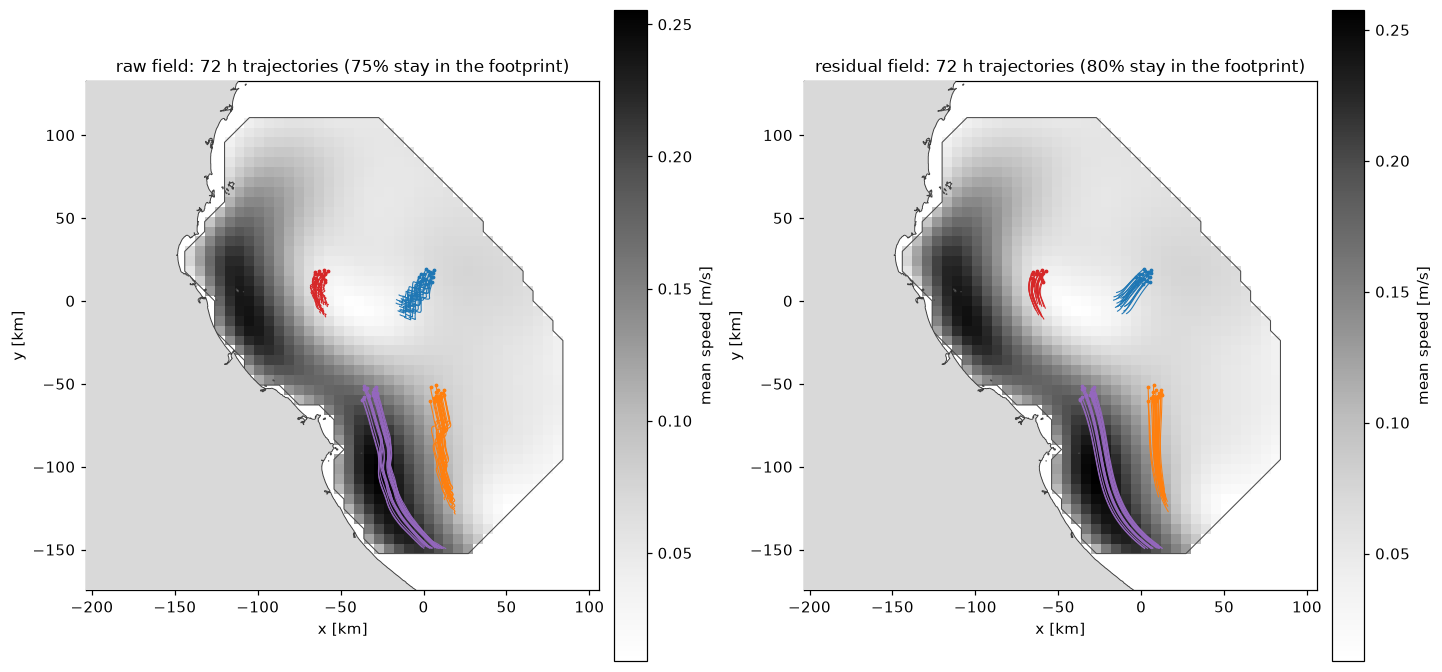

OceanParcels vs lagkit after 24 h: largest difference 8.5e-14 km (100 particles)


In [7]:
vel = {n: lk.grid_interpolator(d, "u", "v", scale=MS_TO_KMH) for n, d in fields.items()}     # km/h
VEL = vel["residual" if DETIDE == "godin" else "raw"]                                        # field used by the diagnostics
FIELD = fields["residual" if DETIDE == "godin" else "raw"]
print(f"diagnostics below use the {'residual (Godin)' if DETIDE == 'godin' else 'raw'} field  (DETIDE = '{DETIDE}')")

xp = np.arange(x[0], x[-1] + DX_MAP / 2, DX_MAP)            # particle grid for all maps
yp = np.arange(y[0], y[-1] + DX_MAP / 2, DX_MAP)
XP, YP = np.meshgrid(xp, yp)
inside = np.isfinite(vel["raw"](XP, YP, t[0])[0]) & np.isfinite(vel["residual"](XP, YP, t[0])[0])
X0G, Y0G = np.where(inside, XP, np.nan), np.where(inside, YP, np.nan)
cx, cy = XP[inside].mean(), YP[inside].mean()
off, half = PATCH
centres = [(cx - off, cy + 0.75 * off), (cx + 0.6 * off, cy + 0.75 * off), (cx - 0.25 * off, cy - off), (cx + 0.75 * off, cy - off)]
px = np.concatenate([c[0] + rng.uniform(-half, half, 100) for c in centres])
py = np.concatenate([c[1] + rng.uniform(-half, half, 100) for c in centres])

cols = ("tab:red", "tab:blue", "tab:purple", "tab:orange")
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, name in zip(axes, ("raw", "residual")):
    Xt, Yt, tt, tau = lk.advect(px, py, t[0], T_TRAJ, DT, vel[name], save_every=2, return_exit=True)
    alive = lk.survival_mask(tt, t[0], tau)
    lk.plot_field(ax, x, y, np.hypot(fields[name].u.mean("time"), fields[name].v.mean("time")), kind="speed", label="mean speed [m/s]", robust=False,
                  title=f"{name} field: {T_TRAJ:.0f} h trajectories ({100 * (tau >= T_TRAJ).mean():.0f}% stay in the footprint)")
    for k, col in enumerate(cols):
        s = slice(100 * k, 100 * (k + 1), 5)
        ax.plot(np.where(alive[:, s], Xt[:, s], np.nan), np.where(alive[:, s], Yt[:, s], np.nan), color=col, lw=0.7)
        ax.plot(Xt[0, s], Yt[0, s], ".", color=col, ms=3)
    deco(ax)
    stay = tau >= T_TRAJ
    path = np.where(alive[1:] & alive[:-1], np.hypot(np.diff(Xt, axis=0), np.diff(Yt, axis=0)), 0).sum(axis=0)
    print(f"{name:8s}: net displacement of the survivors {np.hypot(Xt[-1] - Xt[0], Yt[-1] - Yt[0])[stay].mean():5.1f} km,"
          f" distance travelled along the path {path[stay].mean():5.1f} km, exits {100 * (~stay).mean():.0f}%")
plt.show()

# Cross-check of the integrator with OceanParcels on one patch (24 h, raw field)
xa, ya, tau_a = lk.advect(px[:100], py[:100], t[0], 24.0, DT, vel["raw"], return_exit=True)
xb, yb, tau_b = lk.advect_parcels(px[:100], py[:100], t[0], 24.0, DT, hk, return_exit=True, time_s=3600.0, scale=MS_TO_KMH)
both = (tau_a >= 24) & (tau_b >= 24)
print(f"OceanParcels vs lagkit after 24 h: largest difference {np.hypot(xa - xb, ya - yb)[both].max():.1e} km ({both.sum()} particles)"
      if both.any() else "OceanParcels vs lagkit: no particle of the first patch stayed 24 h in the footprint; exit times agree for "
      f"{100 * (np.abs(tau_a - tau_b) <= DT + 1e-9).mean():.0f}% of them")

**Discussion.** - **Where the water goes.** Particles released near the coast are carried south by the coastal current and leave through the southern edge of the footprint; a quarter of all particles are gone after 72 hours. Offshore patches move a few tens of kilometres and stay.
- **Raw and residual trajectories end in nearly the same place** (net displacement 35 and 39 km). The tide adds small back-and-forth excursions along the way: the distance travelled along the path is only a few kilometres longer in the raw field. A tidal current of 0.2 m/s reversing every 12 hours moves a particle by a few kilometres and brings it back.
- **The integrator is verified on real data:** OceanParcels and `lagkit` agree to round-off after 24 hours.
- The exits are not a defect of the method; they are the limit set by the size of the footprint. Everything that follows has to account for them.

<a id="C6"></a>
## C6. Single-particle statistics (→ [A2](00-lagrangian-theory.ipynb#A2))

Particles are released at random over the whole footprint and followed for `T_STATS` hours. The functions are those of the Bickley notebook, with one addition: averages are taken **over the particles that are still inside the footprint**, and the number of survivors is plotted next to the result.

T_L(u) =  28.6 h (R never crosses zero: lower bound);  <u'^2> = 116 cm2/s2;  K = <u'^2> T_L = 1188 m2/s
T_L(v) =  23.6 h (first zero of R at 57 h);  <v'^2> = 210 cm2/s2;  K = <v'^2> T_L = 1778 m2/s
  after  24 h:  90% of the particles left, rms displacement about the mean: x 8.4 km, y 11.3 km
  after  48 h:  82% of the particles left, rms displacement about the mean: x 14.4 km, y 19.2 km
  after  72 h:  75% of the particles left, rms displacement about the mean: x 18.5 km, y 23.5 km
  after  96 h:  71% of the particles left, rms displacement about the mean: x 20.9 km, y 27.3 km
  after 120 h:  69% of the particles left, rms displacement about the mean: x 22.4 km, y 29.6 km


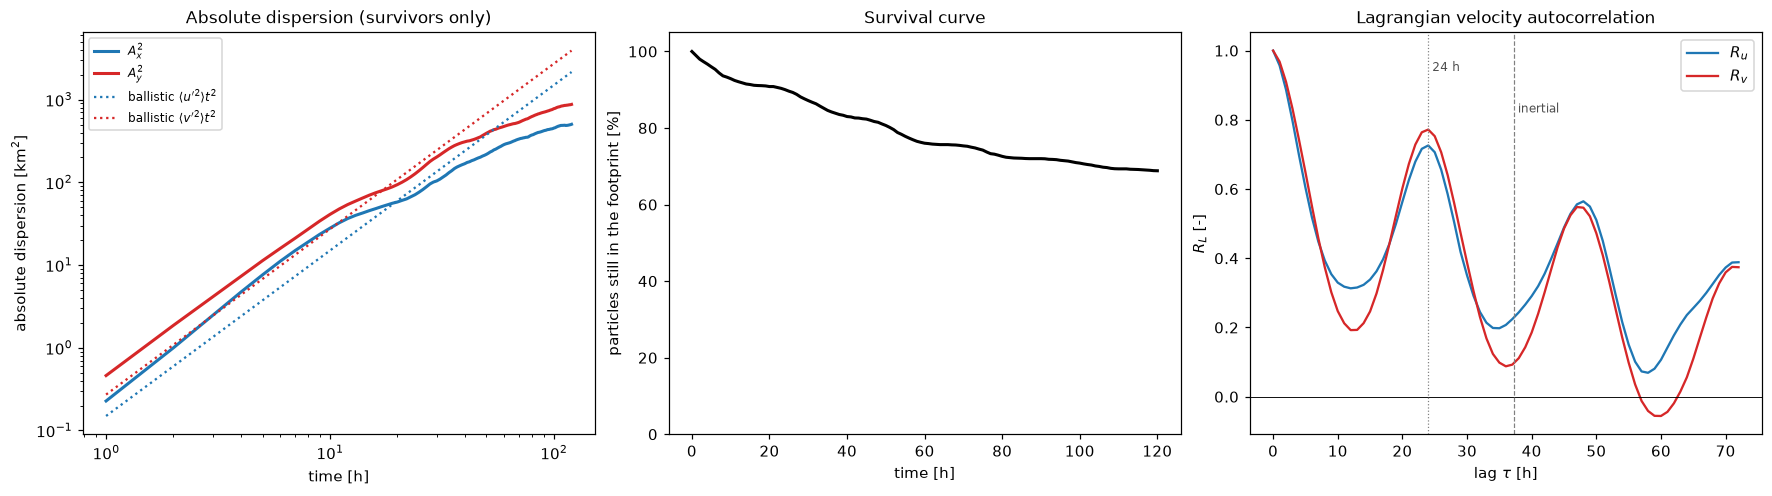

In [8]:
k = rng.choice(inside.sum(), N_SINGLE, replace=False)
Xs, Ys, ts, tau_s = lk.advect(XP[inside][k], YP[inside][k], t[0], T_STATS, DT, VEL, save_every=2, return_exit=True)
alive = lk.survival_mask(ts, t[0], tau_s)
el = ts - ts[0]
Ax2, Ay2, n_alive = lk.absolute_dispersion(Xs, Ys, valid=alive)
with np.errstate(invalid="ignore"):
    Us, Vs = VEL(np.where(alive, Xs, np.nan), np.where(alive, Ys, np.nan), ts.reshape((-1, 1)))
max_lag = int(round(0.6 * T_STATS / (el[1] - el[0])))
Ru = lk.lagrangian_autocorr(Us, max_lag, valid=alive)
Rv = lk.lagrangian_autocorr(Vs, max_lag, valid=alive)
lags = np.arange(max_lag + 1) * (el[1] - el[0])
TLu, iu = lk.integral_timescale(Ru, el[1] - el[0])
TLv, iv = lk.integral_timescale(Rv, el[1] - el[0])
var_u, var_v = np.nanvar(Us), np.nanvar(Vs)
KMH2_TO_M2S = 1e6 / 3600.0
for nm, TL, i0, var in (("u", TLu, iu, var_u), ("v", TLv, iv, var_v)):
    note = f"first zero of R at {lags[i0]:.0f} h" if i0 <= max_lag else "R never crosses zero: lower bound"
    print(f"T_L({nm}) = {TL:5.1f} h ({note});  <{nm}'^2> = {var / MS_TO_KMH ** 2 * 1e4:.0f} cm2/s2;  K = <{nm}'^2> T_L = {var * TL * KMH2_TO_M2S:.0f} m2/s")
for h in (24, 48, 72, 96, 120):
    if h <= T_STATS:
        i = int(np.argmin(np.abs(el - h)))
        print(f"  after {h:3d} h: {100 * n_alive[i] / n_alive[0]:3.0f}% of the particles left, rms displacement about the mean: x {np.sqrt(Ax2[i]):.1f} km, y {np.sqrt(Ay2[i]):.1f} km")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
ax = axes[0]
ax.loglog(el[1:], Ax2[1:], color="tab:blue", lw=2, label="$A_x^2$")
ax.loglog(el[1:], Ay2[1:], color="tab:red", lw=2, label="$A_y^2$")
ax.loglog(el[1:], var_u * el[1:] ** 2, color="tab:blue", ls=":", label=r"ballistic $\langle u'^2\rangle t^2$")
ax.loglog(el[1:], var_v * el[1:] ** 2, color="tab:red", ls=":", label=r"ballistic $\langle v'^2\rangle t^2$")
ax.set(xlabel="time [h]", ylabel="absolute dispersion [km$^2$]", title="Absolute dispersion (survivors only)")
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(el, 100 * n_alive / n_alive[0], "k", lw=2)
ax.set(xlabel="time [h]", ylabel="particles still in the footprint [%]", ylim=(0, 105), title="Survival curve")
ax = axes[2]
ax.plot(lags, Ru, color="tab:blue", label="$R_u$")
ax.plot(lags, Rv, color="tab:red", label="$R_v$")
ax.axhline(0, color="k", lw=0.6)
ax.axvline(T_INERTIAL, color="0.5", ls="--", lw=0.8)
ax.axvline(24.0, color="0.5", ls=":", lw=0.8)
ax.text(24.0, 0.97, " 24 h", fontsize=8, color="0.3", va="top")
ax.text(T_INERTIAL, 0.85, " inertial", fontsize=8, color="0.3", va="top")
ax.set(xlabel=r"lag $\tau$ [h]", ylabel="$R_L$ [-]", title="Lagrangian velocity autocorrelation")
ax.legend()
plt.show()

**Discussion.** - **Survival.** 90% of the particles are still inside after one day, 75% after three, 69% after five. The particles that leave are those in the fast coastal current, so the survivors are a biased sample: the slow part of the flow. Dispersion computed from them is an underestimate.
- **Dispersion.** It grows roughly ballistically during the first day and more slowly afterwards; after 24 hours the cloud has an rms size of about 8 km (east–west) by 11 km (north–south).
- **The autocorrelation oscillates with a 24-hour period** and returns to 0.75 after one day: the Lagrangian velocity is mostly the diurnal tide, which a particle meets again every day. $R_u$ never reaches zero within the record and $R_v$ only after 57 hours.
- **So $T_L$ and $K$ are not meaningful here.** The "first zero crossing" rule gives about a day and diffusivities above 1000 m²/s, but that is the tide, not turbulent decorrelation. On the residual field (Exercise 1) the oscillation disappears and the numbers change completely.
- The record is also short: 120 hours is only five tidal cycles and a few integral time scales, for a statistic that assumes $t\gg T_L$ ([A2](00-lagrangian-theory.ipynb#A2)).

<a id="C7"></a>
## C7. Relative dispersion and FSLE statistic (→ [A3](00-lagrangian-theory.ipynb#A3), [A4](00-lagrangian-theory.ipynb#A4))

**Which particles.** `N_PAIRS` release points are drawn at random inside the footprint. Each gets a partner in a random direction, and this is repeated for `PAIR_N_SEP` initial separations, from `PAIR_D0` = 2 km up to 32 km in steps of $\sqrt2$. A pair is used only while **both** of its particles are inside the footprint.

**Why several initial separations.** The stretching here is weak. Pairs released 2 km apart rarely get beyond a few kilometres within the time they stay in the footprint, so on their own they say nothing about larger scales. Releasing pairs directly at 4, 8, 16, 32 km populates those scales. For the FSLE, a pair contributes to a threshold $\delta_n$ only if it started at or below it, so a pair released at 16 km is never counted as having "crossed" 8 km.

The radar grid spacing is marked on the FSLE plot: below it, two particles see a velocity difference that comes from linear interpolation between the same grid nodes.

initial separation | pairs released | complete after 72 h | rms separation after 72 h | growth of <D^2>, 12-72 h
          2.0 km     |     2943       |       2201          |          2.6 km           | 0.11 1/day
          2.8 km     |     2931       |       2180          |          3.7 km           | 0.11 1/day
          4.0 km     |     2921       |       2170          |          5.2 km           | 0.11 1/day
          5.7 km     |     2880       |       2132          |          7.4 km           | 0.11 1/day
          8.0 km     |     2811       |       2079          |         10.4 km           | 0.11 1/day
         11.3 km     |     2760       |       2030          |         14.7 km           | 0.11 1/day
         16.0 km     |     2678       |       1968          |         20.8 km           | 0.11 1/day
         22.6 km     |     2540       |       1841          |         29.4 km           | 0.11 1/day
         32.0 km     |     2344       |       1669          |         40.0 km  

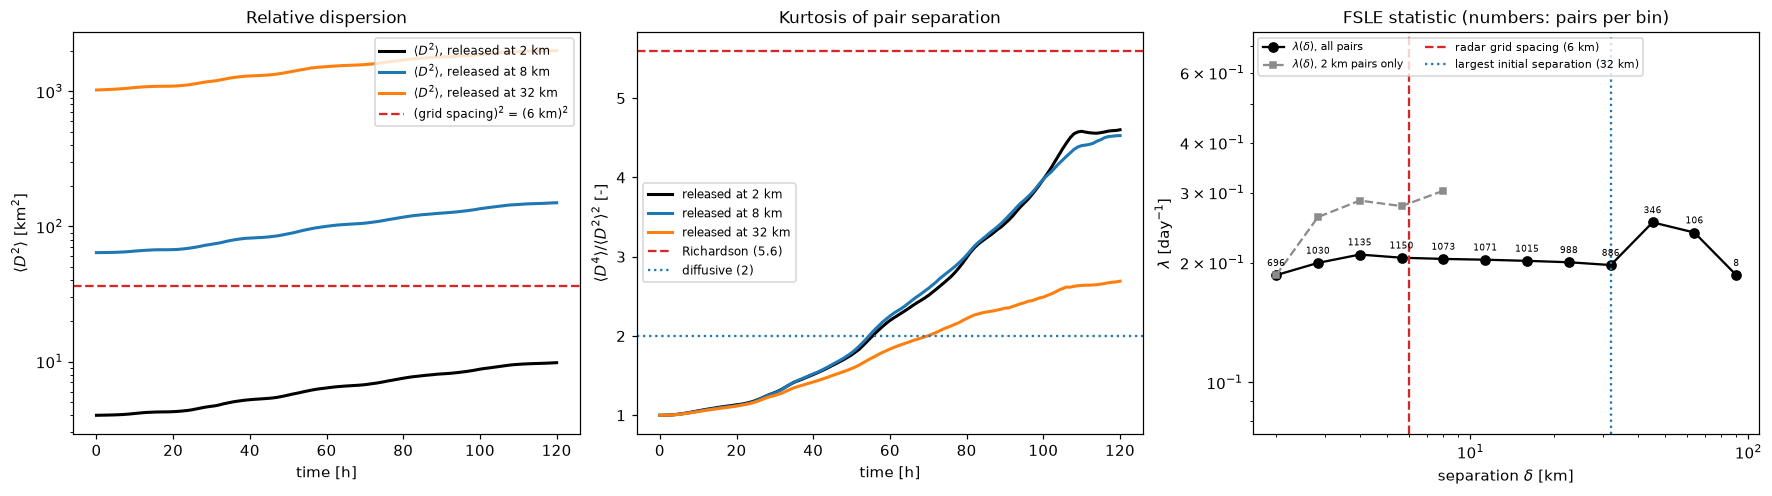

In [9]:
k = rng.choice(inside.sum(), N_PAIRS, replace=False)
xa0, ya0 = XP[inside][k], YP[inside][k]
XA, YA, tp, tA = lk.advect(xa0, ya0, t[0], T_STATS, DT, VEL, save_every=2, return_exit=True)     # first particle of every pair
elp = tp - tp[0]
seps = PAIR_D0 * np.sqrt(2.0) ** np.arange(PAIR_N_SEP)                                       # initial separations [km]
D_by_sep, stats = {}, {}
for d0 in seps:
    ang = rng.uniform(0, 2 * np.pi, N_PAIRS)
    XB, YB, _, tB = lk.advect(xa0 + d0 * np.cos(ang), ya0 + d0 * np.sin(ang), t[0], T_STATS, DT, VEL, save_every=2, return_exit=True)
    tau_pair = np.minimum(tA, tB)
    ok = lk.survival_mask(tp, t[0], tau_pair) & (tau_pair > 0)[None]
    D_by_sep[d0] = np.where(ok, lk.pair_separation(XA, YA, XB, YB), np.nan)
    stats[d0] = lk.relative_dispersion(D_by_sep[d0], elp)                                    # D2, Krel, kurtosis, n

print("initial separation | pairs released | complete after 72 h | rms separation after 72 h | growth of <D^2>, 12-72 h")
i72 = int(np.argmin(np.abs(elp - 72)))
rates = {}
for d0 in seps:
    D2_, _, _, n_ = stats[d0]
    fit = (elp >= 12) & (elp <= 72) & (n_ > 100)
    rates[d0] = np.polyfit(elp[fit], np.log(D2_[fit]), 1)[0] / 2 * 24 if fit.sum() > 3 else np.nan
    print(f"  {d0:11.1f} km     | {int(n_[0]):8d}       | {int(n_[i72]):10d}          | {np.sqrt(D2_[i72]):12.1f} km           | {rates[d0]:.2f} 1/day")

# FSLE from all the pairs together: thresholds PAIR_D0 * sqrt(2)**n
D_all = np.concatenate(list(D_by_sep.values()), axis=1)
delta, lam, n_bin, _ = lk.fsle_statistic(D_all, tp, PAIR_D0)
print("\nFSLE:  " + ",  ".join(f"{d:.0f} km: {l * 24:.2f}/day (n={n})" for d, l, n in zip(delta, lam, n_bin)))
# the same from the 2 km pairs alone, as in a single-separation experiment
delta1, lam1, n1, _ = lk.fsle_statistic(D_by_sep[seps[0]], tp, PAIR_D0)
print("2 km pairs only:  " + ",  ".join(f"{d:.0f} km: {l * 24:.2f}/day (n={n})" for d, l, n in zip(delta1, lam1, n1)))

show = [seps[0], seps[4], seps[-1]] if PAIR_N_SEP >= 5 else list(seps)
cols_ = ("k", "tab:blue", "tab:orange")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
ax = axes[0]
for d0, col in zip(show, cols_):
    ax.semilogy(elp, stats[d0][0], color=col, lw=2, label=rf"$\langle D^2\rangle$, released at {d0:.0f} km")
ax.axhline(dx ** 2, color="tab:red", ls="--", label=f"(grid spacing)$^2$ = ({dx:.0f} km)$^2$")
ax.set(xlabel="time [h]", ylabel=r"$\langle D^2\rangle$ [km$^2$]", title="Relative dispersion")
ax.legend(fontsize=8)
ax = axes[1]
for d0, col in zip(show, cols_):
    ax.plot(elp, stats[d0][2], color=col, lw=2, label=f"released at {d0:.0f} km")
ax.axhline(5.6, color="tab:red", ls="--", label="Richardson (5.6)")
ax.axhline(2.0, color="tab:blue", ls=":", label="diffusive (2)")
ax.set(xlabel="time [h]", ylabel=r"$\langle D^4\rangle/\langle D^2\rangle^2$ [-]", title="Kurtosis of pair separation")
ax.legend(fontsize=8)
ax = axes[2]
g = np.isfinite(lam) & (lam > 0)
ax.loglog(delta[g], lam[g] * 24, "o-k", label=r"$\lambda(\delta)$, all pairs")
g1 = np.isfinite(lam1) & (lam1 > 0)
ax.loglog(delta1[g1], lam1[g1] * 24, "s--", color="0.55", ms=4, label=r"$\lambda(\delta)$, 2 km pairs only")
for d_, l_, n_ in zip(delta[g], lam[g], n_bin[g]):
    ax.annotate(str(n_), (d_, l_ * 24), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=6)
ax.axvline(dx, color="tab:red", ls="--", label=f"radar grid spacing ({dx:.0f} km)")
ax.axvline(seps[-1], color="tab:blue", ls=":", label=f"largest initial separation ({seps[-1]:.0f} km)")
ax.set(xlabel=r"separation $\delta$ [km]", ylabel=r"$\lambda$ [day$^{-1}$]", title="FSLE statistic (numbers: pairs per bin)",
       ylim=(0.4 * np.nanmin(lam[g]) * 24, 2.5 * np.nanmax(np.concatenate([lam[g], lam1[g1]])) * 24))
ax.legend(fontsize=7, loc="upper left", ncol=2)
plt.show()

**Discussion.** - **The FSLE now covers 2 to 64 km.** With pairs released at nine separations, every threshold up to 32 km is crossed by about 1000 pairs. The grey curve is what the 2 km pairs alone give: it stops at 8 km with 13 pairs.
- **A plateau: $\lambda\approx0.20$ day⁻¹ from 2 to 32 km.** Pairs 2 km apart and pairs 32 km apart separate at the same relative rate. This is the non-local regime of [A4](00-lagrangian-theory.ipynb#A4), as in the Bickley jet: separation at all these scales is driven by the same large-scale strain and shear, here that of the coastal current. The left panel says the same thing: the $\langle D^2\rangle$ curves are parallel on the semilog plot, with a growth rate of 0.11 day⁻¹ whatever the initial separation.
- **Survivorship, twice.** (1) Beyond the largest initial separation (32 km, dotted line) a bin only contains pairs that grew into it: few pairs, and the fastest ones, so $\lambda$ jumps up. Do not interpret those points. (2) Even on the plateau only about a third of the released pairs cross a given threshold within 120 hours; the FSLE is the rate of that faster third, which is why it is about twice the rate of $\langle D^2\rangle$. The grey curve shows the same bias in a stronger form: its values climb to 0.3 day⁻¹ because only the fastest 2 km pairs reach the next thresholds.
- **What the plateau does and does not say.** Below the 6 km grid spacing the velocity difference between two particles comes from linear interpolation, so a constant $\lambda$ there is built in. Above it the pairs feel resolved gradients, and the plateau is a property of this velocity product. The 2DVar field is smooth, so it cannot show the scale-dependent (local) dispersion that real drifters might reveal at 5–30 km.
- The kurtosis grows steadily to about 4.5 for the small separations: the pairs become more and more unequal, as expected when a minority separates exponentially.

<a id="C8"></a>
## C8. FTLE (→ [A5](00-lagrangian-theory.ipynb#A5))

One particle per point of a `DX_MAP` grid over the footprint, integrated for `T_FTLE` hours: forward from the start of the period (repelling structures at that time) and backward from its end (attracting structures at that time).

The footprint is open, so particles leave. `lk.ftle_from_trajectories` handles this consistently: at each point the flow map is taken at the last time at which **all** the points of its finite-difference stencil were still inside, and points for which that time is shorter than half of `T_FTLE` are masked.

The calculation is done for the raw and for the residual field, to see what the tide does to the structures.

36150 particles x 4 integrations: 19 s
raw      forward : defined on  88% of the footprint; median 0.11, 90th percentile 0.37, max 0.73 1/day; negative values: 3%
raw      backward: defined on  88% of the footprint; median 0.08, 90th percentile 0.18, max 0.47 1/day; negative values: 1%
residual forward : defined on  89% of the footprint; median 0.11, 90th percentile 0.35, max 0.70 1/day; negative values: 3%
residual backward: defined on  92% of the footprint; median 0.08, 90th percentile 0.18, max 0.50 1/day; negative values: 1%


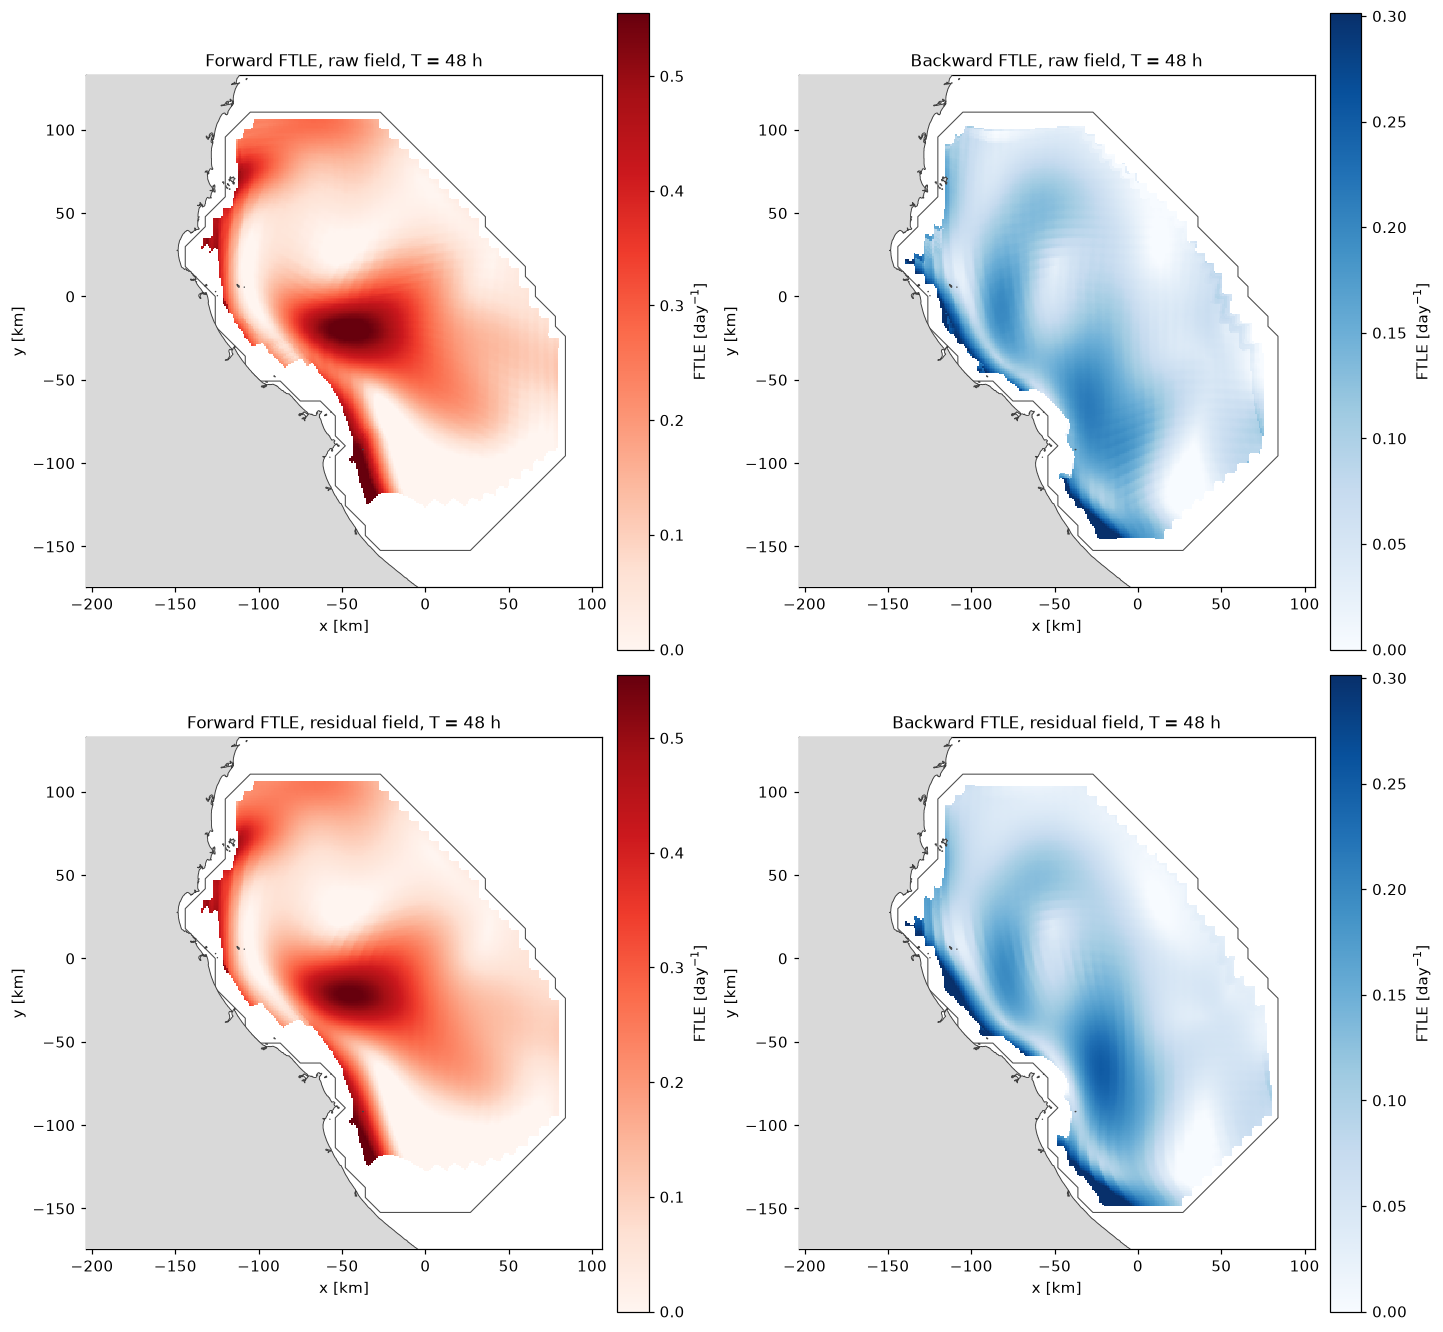

pattern correlation raw vs residual, fwd: +0.99
pattern correlation raw vs residual, bwd: +0.95


In [10]:
def ftle_maps(velocity):
    out = {}
    for label, t0_, T in (("fwd", t[0], T_FTLE), ("bwd", t[-1], -T_FTLE)):
        Xs_, Ys_, ts_, tau_ = lk.advect(X0G, Y0G, t0_, T, DT, velocity, save_every=4, return_exit=True)
        out[label], out[label + "_tau"] = lk.ftle_from_trajectories(Xs_, Ys_, ts_, tau_, DX_MAP, DX_MAP)
    return out


tic = time.time()
ftle = {n: ftle_maps(v) for n, v in vel.items()}
print(f"{int(inside.sum())} particles x 4 integrations: {time.time() - tic:.0f} s")
vmax = {k_: np.nanpercentile(np.concatenate([ftle[n][k_].ravel() for n in ftle]), 99) * 24 for k_ in ("fwd", "bwd")}
fig, axes = plt.subplots(2, 2, figsize=(13, 12), constrained_layout=True)
for row, name in zip(axes, ("raw", "residual")):
    for ax, k_, kind, word in zip(row, ("fwd", "bwd"), ("ftle_fwd", "ftle_bwd"), ("Forward", "Backward")):
        F = ftle[name][k_]
        lk.plot_field(ax, xp, yp, F * 24, kind=kind, label="FTLE [day$^{-1}$]", vmin=0, vmax=vmax[k_],
                      title=f"{word} FTLE, {name} field, T = {T_FTLE:.0f} h")
        deco(ax)
        print(f"{name:8s} {word.lower():8s}: defined on {100 * np.isfinite(F).sum() / inside.sum():3.0f}% of the footprint; median {np.nanmedian(F) * 24:.2f},"
              f" 90th percentile {np.nanpercentile(F, 90) * 24:.2f}, max {np.nanmax(F) * 24:.2f} 1/day; negative values: {100 * np.nanmean(F < 0):.0f}%")
plt.show()
for k_ in ("fwd", "bwd"):
    m = np.isfinite(ftle["raw"][k_]) & np.isfinite(ftle["residual"][k_])
    print(f"pattern correlation raw vs residual, {k_}: {np.corrcoef(ftle['raw'][k_][m], ftle['residual'][k_][m])[0, 1]:+.2f}")

**Discussion.** - **Coverage of the map.** About 90% of the footprint keeps a value for $T$ = 48 h; the rest, along the southern and coastal edges, lost its particles too early and is blank.
- **Weak, broad structures.** Typical values are 0.1 day⁻¹ (median) and 0.2–0.4 day⁻¹ (90th percentile), with a maximum of 0.7 day⁻¹. The maps show patches tens of kilometres wide, not the thin ridges of the Bickley jet. The strongest forward stretching is where the coastal current accelerates and peels away from the slower water offshore; the strongest backward values lie along the coast, where water converges onto the current.
- **A few negative values** (1–3% of the points). They mean that a fluid element shrank in every direction, which cannot happen in a non-divergent flow. Surface currents are divergent ([A1](00-lagrangian-theory.ipynb#A1)).
- **The tide hardly changes the structures.** Raw and residual maps are almost identical (pattern correlation 0.99 forward, 0.95 backward), although the filter removed 85% of the velocity variance. The diurnal tide here is a large-scale oscillation: it moves neighbouring particles together and brings them back, so it produces little net stretching. The structures are set by the residual flow.
- This is a property of this place and this product, not a general rule: where the tidal current has strong horizontal gradients (straits, headlands, shallow banks) it does create Lagrangian structures.

<a id="C9"></a>
## C9. FSLE map (→ [A6](00-lagrangian-theory.ipynb#A6))

The FSLE map needs an initial and a final separation. A common choice in the literature for satellite-derived currents is a final separation of many grid cells. The cell below first asks a simpler question: over `FSLE_TMAX` hours, what fraction of the footprint reaches a final separation of 1.2, 1.5, 2 or 4 times the initial one? Each point ends in one of three states, which must be kept apart:

- **reached** $\delta_f$: $\lambda=\ln(\delta_f/\delta_0)/\tau$;
- **never separated** within the time available: $\lambda=0$, a real result;
- **left the footprint first**: no value. This is not zero.

backward from the end of the period, delta_0 = 1.0 km, T_max = 96 h
  delta_f/delta_0 | reached | never separated | left first | smallest non-zero value [1/day]


              1.2 |     58% |             18% |        25% | 0.05


              1.5 |     28% |             45% |        28% | 0.10


              2.0 |      7% |             65% |        28% | 0.17


              4.0 |      0% |             72% |        28% | 0.35


  same ratio 1.5 with delta_0 doubled (2.0 km): reached 28%  (with 1.0 km: 28%)


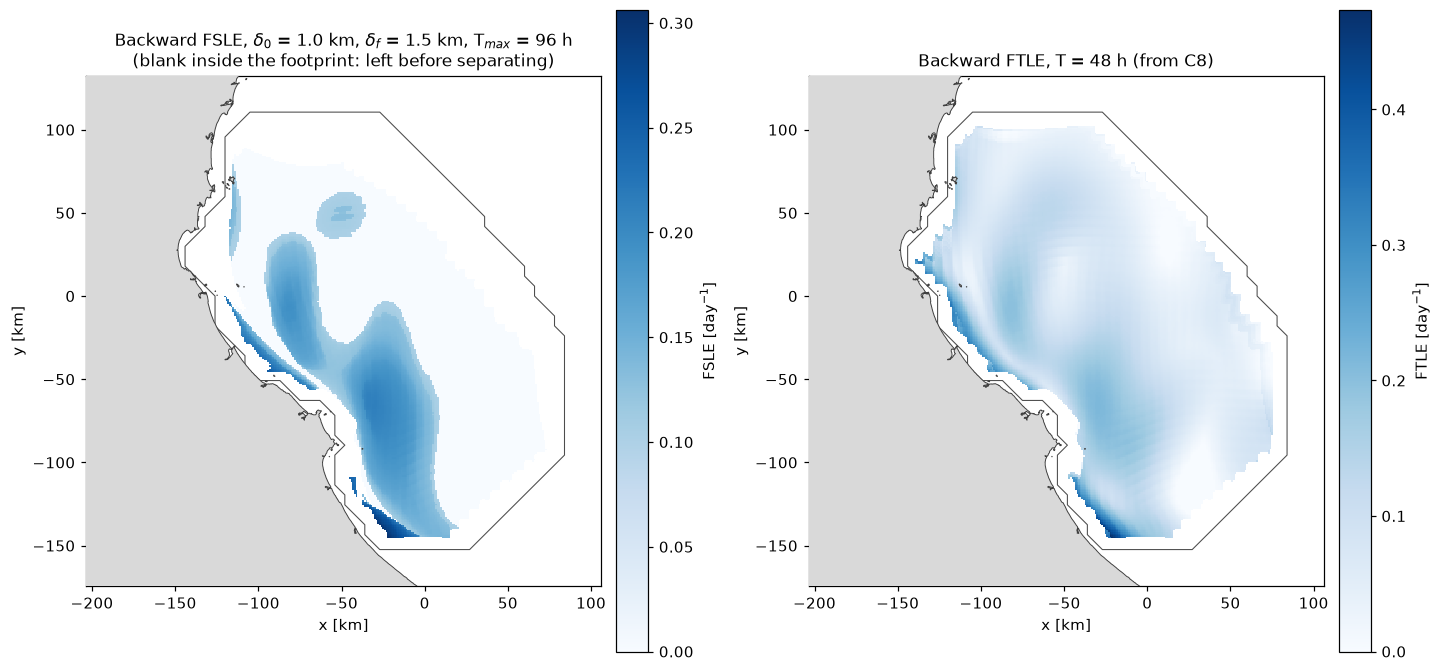

In [11]:
x_in, y_in = XP[inside], YP[inside]
print(f"backward from the end of the period, delta_0 = {FSLE_D0} km, T_max = {FSLE_TMAX:.0f} h")
print("  delta_f/delta_0 | reached | never separated | left first | smallest non-zero value [1/day]")
fsle_runs = {}
for ratio in (1.2, 1.5, 2.0, 4.0):
    lam_, tau_, st_ = lk.fsle_map(x_in, y_in, t[-1], -FSLE_TMAX, DT, FSLE_D0, ratio * FSLE_D0, VEL)
    fsle_runs[ratio] = (lam_, st_)
    print(f"  {ratio:15.1f} | {100 * (st_ == 1).mean():6.0f}% | {100 * (st_ == 0).mean():14.0f}% | {100 * (st_ == 2).mean():9.0f}% | {np.log(ratio) / FSLE_TMAX * 24:.2f}")
lam_, tau_, st_ = lk.fsle_map(x_in, y_in, t[-1], -FSLE_TMAX, DT, 2 * FSLE_D0, 2 * FSLE_D0 * FSLE_RATIO, VEL)
print(f"  same ratio {FSLE_RATIO} with delta_0 doubled ({2 * FSLE_D0} km): reached {100 * (st_ == 1).mean():.0f}%  (with {FSLE_D0} km: {100 * (fsle_runs[FSLE_RATIO][1] == 1).mean():.0f}%)")

lam_, st_ = fsle_runs[FSLE_RATIO]
F = np.full(XP.shape, np.nan)
F[inside] = np.where(st_ == 1, lam_ * 24, np.where(st_ == 0, 0.0, np.nan))
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
lk.plot_field(axes[0], xp, yp, F, kind="fsle", label="FSLE [day$^{-1}$]", vmin=0,
              title=rf"Backward FSLE, $\delta_0$ = {FSLE_D0} km, $\delta_f$ = {FSLE_D0 * FSLE_RATIO} km, T$_{{max}}$ = {FSLE_TMAX:.0f} h" + "\n(blank inside the footprint: left before separating)")
lk.plot_field(axes[1], xp, yp, ftle["residual" if DETIDE == "godin" else "raw"]["bwd"] * 24, kind="ftle_bwd", label="FTLE [day$^{-1}$]", vmin=0,
              title=f"Backward FTLE, T = {T_FTLE:.0f} h (from C8)")
for ax in axes:
    deco(ax)
plt.show()

**Discussion.** - **The classical parameters are out of reach.** Not a single point separates by a factor of 4 in 96 hours, and only 7% by a factor of 2. The stretching is too weak and the footprint too small: about a quarter of the points leave before any threshold is reached.
- **Only the ratio matters.** Doubling $\delta_0$ at the same ratio gives the same result. Below the grid spacing the velocity is interpolated linearly, so separations grow by a factor that does not depend on their size.
- With a ratio of 1.5 the map can be drawn (28% of the points reach $\delta_f$), and it highlights the same regions as the backward FTLE. With such a small ratio it is essentially a thresholded FTLE and carries no information about finite scales.
- **Three kinds of points, three treatments:** a value where $\delta_f$ was reached, zero where the pair never separated, and *blank* where the particles left first. Setting the last kind to zero would paint the coastal current, the most active part of the flow, as a quiet region.
- An FSLE map earns its name when $\delta_f$ is several grid cells. That needs stronger stretching, a larger domain, or both.

<a id="C10"></a>
## C10. LAVD, eddies, and Okubo–Weiss (→ [A7](00-lagrangian-theory.ipynb#A7), [A8](00-lagrangian-theory.ipynb#A8))

The vorticity is computed from the gridded velocity by centred differences; its mean over the footprint at each hour is the $\bar\omega(t)$ of (A7.2). `lk.extract_eddies` then looks for the outermost nearly convex LAVD contour around each maximum.

With real data two safeguards are added to what was done for the Bickley jet:

- a **minimum rotation**. The LAVD is twice the angle turned by a fluid element relative to the mean rotation, so $\mathrm{LAVD}/4\pi$ is a number of turns. A convex contour around a place where the water turns a small fraction of a turn is not an eddy. Here `MIN_ROTATION` turns are required;
- a **material test**: every boundary is advected for `T_LAVD` and its deformation measured, as in the Bickley notebook.

For comparison, Okubo–Weiss eddies are computed from the velocity averaged over the same `T_LAVD` hours (a single hourly snapshot is dominated by the tide).

LAVD over 72 h: defined on 65% of the footprint; maximum = 2.32 = 0.18 turns
convex LAVD contours: 1;  with at least 0.5 turn: 0
  LAVD contour 0: centre (-85, 31) km, R = 32 km, 0.15 turns -> not an eddy (too little rotation);  perimeter x0.94 after 72 h, 100% of the boundary stays inside
Okubo-Weiss of the 72 h mean flow: 3 regions below -0.2 sigma_W, 1 with a closed boundary
  OW region 0: cyclonic, centre (-93, 12) km, R = 36 km; perimeter x1.04 after 29 h, 82% stays inside


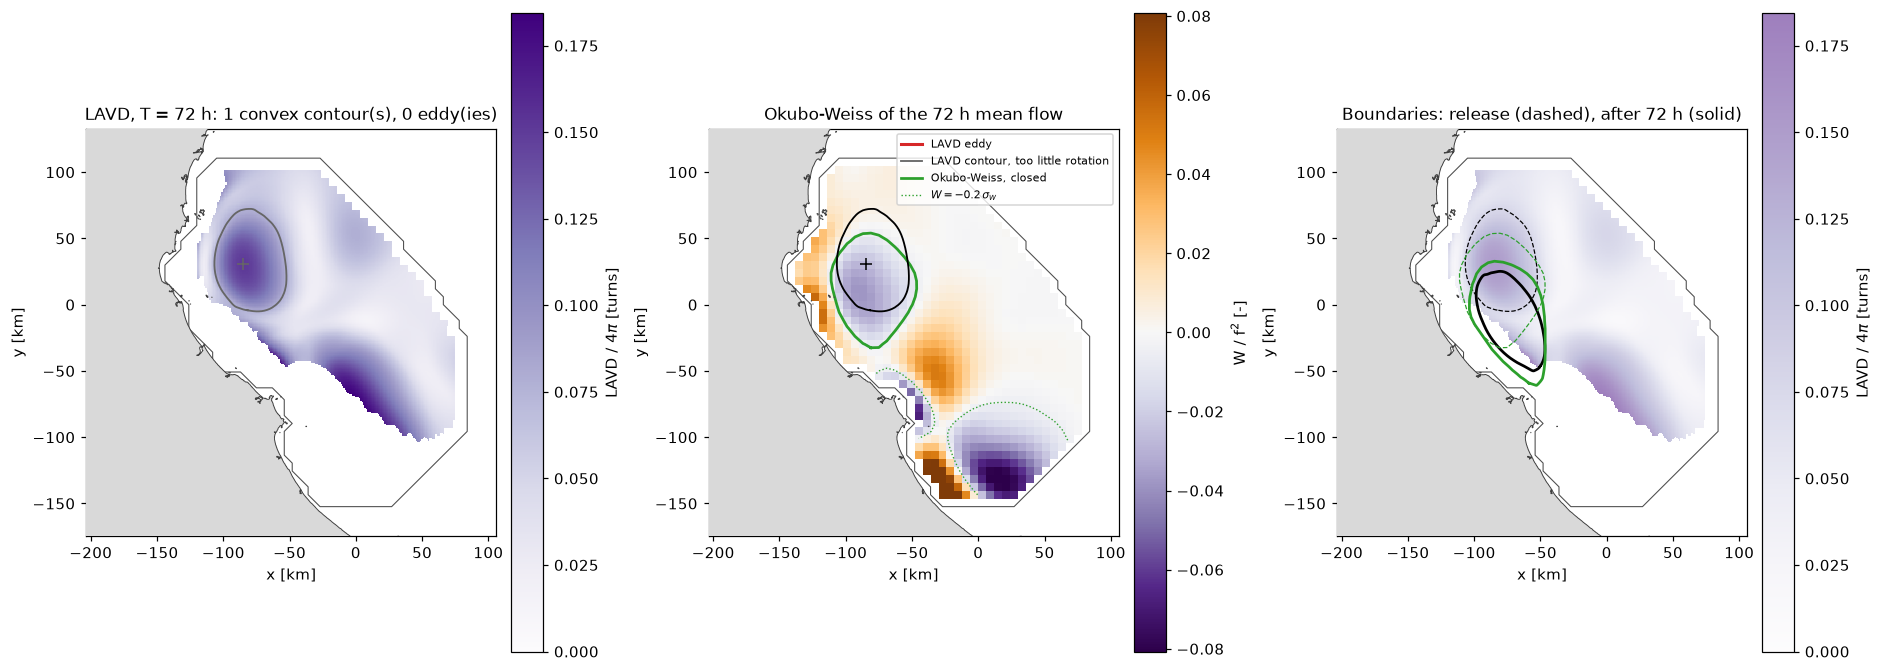


Total run time of the notebook: 145 s


In [12]:
vort_fun = lk.grid_interpolator(FIELD.assign(vort=(("time", "y", "x"), lk.vorticity(FIELD.u.values * MS_TO_KMH, FIELD.v.values * MS_TO_KMH, dx, dy))), "vort")
om_field = lk.vorticity(FIELD.u.values * MS_TO_KMH, FIELD.v.values * MS_TO_KMH, dx, dy)
om_mean = np.nan_to_num(np.nanmean(om_field, axis=(1, 2)))
LAVD, tau_l = lk.lavd(X0G, Y0G, t[0], T_LAVD, DT, VEL, vort_fun, lambda tq: float(np.interp(tq, t, om_mean)), return_exit=True)
contours = lk.extract_eddies(xp, yp, LAVD, peak_quantile=0.9, box=EDDY_BOX, n_levels=100, cd_max=CD_MAX, min_area=np.pi * EDDY_MIN_R ** 2)
eddies = [e for e in contours if e["peak"] / (4 * np.pi) >= MIN_ROTATION]
print(f"LAVD over {T_LAVD:.0f} h: defined on {100 * np.isfinite(LAVD).sum() / inside.sum():.0f}% of the footprint; maximum = {np.nanmax(LAVD):.2f} = {np.nanmax(LAVD) / (4 * np.pi):.2f} turns")
print(f"convex LAVD contours: {len(contours)};  with at least {MIN_ROTATION} turn: {len(eddies)}")
curves = {}
for n_, e in enumerate(contours):
    c_ = curves[("lavd", n_)] = lk.advect_curve(e["boundary"], t[0], T_LAVD, DT, VEL)
    print(f"  LAVD contour {n_}: centre ({e['xc']:.0f}, {e['yc']:.0f}) km, R = {e['r_eq']:.0f} km, {e['peak'] / (4 * np.pi):.2f} turns ->"
          f" {'EDDY' if e in eddies else 'not an eddy (too little rotation)'};  perimeter x{c_['ratio']:.2f} after {c_['t_common']:.0f} h, {100 * c_['stay']:.0f}% of the boundary stays inside")

n_mean = int(round(T_LAVD)) + 1
um_w, vm_w = FIELD.u.values[:n_mean].mean(axis=0) * MS_TO_KMH, FIELD.v.values[:n_mean].mean(axis=0) * MS_TO_KMH
W, W_level, ow, n_regions = lk.ow_eddies(x, y, um_w, vm_w)
print(f"Okubo-Weiss of the {T_LAVD:.0f} h mean flow: {n_regions} regions below -0.2 sigma_W, {len(ow)} with a closed boundary")
for n_, o in enumerate(ow):
    c_ = curves[("ow", n_)] = lk.advect_curve(o["boundary"], t[0], T_LAVD, DT, VEL)
    print(f"  OW region {n_}: {'cyclonic' if o['cyclonic'] else 'anticyclonic'}, centre ({o['xc']:.0f}, {o['yc']:.0f}) km, R = {o['r_eq']:.0f} km;"
          f" perimeter x{c_['ratio']:.2f} after {c_['t_common']:.0f} h, {100 * c_['stay']:.0f}% stays inside")

fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
lk.plot_field(axes[0], xp, yp, LAVD / (4 * np.pi), kind="lavd", label=r"LAVD / 4$\pi$ [turns]", robust=False, vmin=0,
              title=f"LAVD, T = {T_LAVD:.0f} h: {len(contours)} convex contour(s), {len(eddies)} eddy(ies)")
lk.plot_eddies(axes[0], [e for e in contours if e not in eddies], color="0.4", lw=1.2)
lk.plot_eddies(axes[0], eddies, color="tab:red", lw=2)
lk.plot_field(axes[1], x, y, W / F_COR ** 2, kind="okubo_weiss", label=r"W / f$^2$ [-]", title=f"Okubo-Weiss of the {T_LAVD:.0f} h mean flow")
axes[1].contour(x, y, np.ma.masked_invalid(W), levels=[W_level], colors="tab:green", linewidths=0.9, linestyles=":")
for o in ow:
    axes[1].plot(*o["boundary"].T, color="tab:green", lw=1.8)
lk.plot_eddies(axes[1], contours, color="k", lw=1.2)
lk.plot_field(axes[2], xp, yp, LAVD / (4 * np.pi), kind="lavd", label=r"LAVD / 4$\pi$ [turns]", robust=False, vmin=0, alpha=0.5,
              title=f"Boundaries: release (dashed), after {T_LAVD:.0f} h (solid)")
for (kind_, n_), c_ in curves.items():
    col = "k" if kind_ == "lavd" else "tab:green"
    axes[2].plot(*c_["initial"].T, color=col, lw=0.8, ls="--")
    axes[2].plot(*c_["final"].T, color=col, lw=1.8)
handles = [Line2D([], [], color="tab:red", lw=2, label="LAVD eddy"), Line2D([], [], color="0.4", lw=1.2, label="LAVD contour, too little rotation"),
           Line2D([], [], color="tab:green", lw=1.8, label="Okubo-Weiss, closed"), Line2D([], [], color="tab:green", lw=0.9, ls=":", label=r"$W=-0.2\,\sigma_W$")]
axes[1].legend(handles=handles, fontsize=7, loc="upper right")
for ax in axes:
    deco(ax)
plt.show()
print(f"\nTotal run time of the notebook: {time.time() - t_notebook:.0f} s")

**Discussion.** - **No eddy.** The largest LAVD value corresponds to 0.18 turns in 72 hours. The extraction does find one convex contour (radius 32 km, in the north-west), but the water inside turns by 0.15 turns: it fails the minimum-rotation test.
- **Coherent, but not an eddy.** The advected boundary keeps its perimeter (×0.94) and stays inside the footprint. The patch is not torn apart, simply because the flow there is weak and smooth. In a weak flow almost any closed curve stays "coherent" for three days, which is why the advection test alone is not sufficient either.
- **Okubo–Weiss marks the same place:** a cyclonic region of similar size (36 km) in the mean flow, plus two regions cut by the edge of the footprint. It has no way of saying that the rotation is too slow to matter, and part of its boundary leaves the footprint.
- **The LAVD is defined on two thirds of the footprint only**: the rest left within 72 hours. The coastal current, where the vorticity is strongest, is exactly where no value can be computed.
- "No coherent eddy in this window" is a result. Tuning `CD_MAX`, `MIN_ROTATION` or the period until a contour appears would be fitting the method to the wish (Exercise 5).

<a id="C11"></a>
## C11. Summary

| Diagnostic | Result on this data set | What limited it |
|---|---|---|
| Trajectories | southward coastal current; a quarter of the particles leave in 3 days | size of the footprint |
| Single-particle statistics | dispersion of about 10 km in a day; autocorrelation oscillating at 24 h | the tide dominates; survivors are a biased sample; short record |
| Relative dispersion, FSLE statistic | plateau of 0.2 day⁻¹ from 2 to 32 km (non-local regime) | needs pairs released at many separations; survivors only; smooth field hides any scale dependence |
| FTLE | broad patches, 0.1–0.4 day⁻¹; the same with and without the tide | smooth gap-filled field; exits at the edges |
| FSLE map | possible only for a separation ratio of about 1.5 | weak stretching; then equivalent to a thresholded FTLE |
| LAVD | one convex contour, 0.15 turns: no eddy | weak rotation; one third of the footprint lost to exits |
| Okubo–Weiss | one closed cyclonic region at the same place | says nothing about rotation rate or material coherence |

**General lessons**

1. Lagrangian diagnostics need a **continuous** velocity field. With gaps, particles are lost within hours. Gap filling makes the analysis possible, and it also decides how much small-scale structure is left to find.
2. Always report **how many particles survive**. Every average in this notebook is over survivors, and every map has points that could not be computed.
3. The **integration time** is limited by the size of the footprint divided by the speed of the flow, not by what the theory would like.
4. Separations **below the grid spacing** measure the interpolation. To learn something about larger scales, pairs must be **released at those scales**; waiting for close pairs to grow is not enough in a weak flow and a small domain.
5. Decide whether the question is about **where things go** (keep the tide) or about the **slow circulation** (remove it), and compute the diagnostics on the corresponding field.
6. Detecting an eddy needs more than a closed contour: check the **rotation** and test the boundary by **advecting** it.

## Exercises

1. **Tides.** Set `DETIDE = "godin"` and re-run from C5. How do the trajectories, the Lagrangian time scales of C6 and the FSLE of C7 change? For a search-and-rescue case today, which field would you use, and why?
2. **Integration time against domain size.** Recompute the FTLE of C8 for `T_FTLE` = 24, 72 and 120 h. Plot the fraction of the footprint that keeps a value against `T_FTLE`. What is the longest useful integration time here? Estimate it beforehand from the footprint size and the mean speed printed in C2. Then recompute the FSLE of C7 with `T_STATS` = 60 and 240 h: how does the plateau change, and why?
3. **Another period.** The file holds the whole of January 2015. Change the period in C0 to `("2015-01-03", "2015-01-12")` and to `("2015-01-19", "2015-01-28")`. Compare the mean current, the survival curve and the FTLE maps with the case studied here. How representative is one ten-day window?
4. **Gap filling changes the answer.** In C4, compute the forward FTLE over 48 h from the field with gaps after the simple filling, and compare it with the map from the complete field in C8. Repeat with `GAP_MAX_HOURS` = 3 and 12, and with a 24-hour outage of the whole radar. Which parts of the map would you trust?
5. **Minimum rotation.** Set `MIN_ROTATION = 0` in C0. What does the LAVD method report? Advect the boundary as in C10: does it stay coherent? Explain why "coherent" and "eddy" are not the same thing in a weak, smooth flow.
6. **Skill against a drifter.** If you have a drifter track (time, longitude, latitude), release a particle at each drifter position every 6 h, advect it for 24 h in the radar field and compute `lk.liu_weisberg_skill` against the drifter. Do it for the raw and for the residual field.

## References

- Godin, G. (1972). *The Analysis of Tides*. University of Toronto Press, 264 pp.
- Haller, G., Hadjighasem, A., Farazmand, M., & Huhn, F. (2016). Defining coherent vortices objectively from the vorticity. *Journal of Fluid Mechanics*, 795, 136–173. https://doi.org/10.1017/jfm.2016.151
- Liu, Y., & Weisberg, R. H. (2011). Evaluation of trajectory modeling in different dynamic regions using normalized cumulative Lagrangian separation. *Journal of Geophysical Research*, 116, C09013. https://doi.org/10.1029/2010JC006837
- Tran, M. C., Sentchev, A., Berti, S., Ayoub, N. K., & Nguyen-Duy, T. (2022). Assessment of relative dispersion in the Gulf of Tonkin using numerical modeling and HF radar observations of surface currents. *Continental Shelf Research*, 245, 104784. https://doi.org/10.1016/j.csr.2022.104784
- Yaremchuk, M., & Sentchev, A. (2009). Mapping radar-derived sea surface currents with a variational method. *Continental Shelf Research*, 29(14), 1711–1722. https://doi.org/10.1016/j.csr.2009.05.016

The references for the methods themselves (FTLE, FSLE, LAVD, Okubo–Weiss, dispersion statistics) are listed in [`00-lagrangian-theory.ipynb`](00-lagrangian-theory.ipynb).

Data: Gulf of Tonkin HF-radar currents re-processed with 2DVar (file provided for the course). Coastline: GSHHS, through cartopy. Software: OceanParcels, https://parcels-code.org.